ThinCurr Python Example: Time-domain model of nested tori joined by ribs {#doc_tCurr_junctions_td}
==========
In this example we run a time-domain simulation of a structure with junctions: two nested, concentric tori joined
by four ribs that run all the way around the torus in the toroidal direction (a simple model of a double-walled
vacuum vessel). Each rib meets each torus along a closed toroidal circle, so the mesh has eight closed junction
lines. The geometry and drive follow \ref doc_tCurr_hodlr: the inner torus has the same major and minor radius as the
torus in that example (1 m and 0.5 m), the outer torus is concentric with a minor radius 5 cm larger (0.55 m), and the
same circular I-coil drives the model.

Junctions are handled by splitting the mesh along them and enforcing current conservation across each junction edge,
see \ref doc_tw_main_junctions and \ref doc_tCurr_junctions.

**Note:** Running this example requires the [h5py](https://www.h5py.org/) and [pyvista](https://pyvista.org/) python packages, which are installable using `pip` or other standard methods.

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
try:
    import pyvista
    pyvista.set_jupyter_backend('static') # Comment to enable interactive PyVista plots
    have_pyvista = True
except ImportError:
    print("pyvista not found, 3D plots will be skipped")
    have_pyvista = False
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load ThinCurr library

To load the ThinCurr python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` for binaries on macOS).

In [2]:
thincurr_python_path = os.getenv('OFT_ROOTPATH')
if thincurr_python_path is not None:
    sys.path.append(os.path.join(thincurr_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.ThinCurr import ThinCurr
from OpenFUSIONToolkit.ThinCurr.sensor import Mirnov, save_sensors
from OpenFUSIONToolkit.ThinCurr.coils import ThinCurr_Icoil
from OpenFUSIONToolkit.ThinCurr.meshing import write_ThinCurr_mesh
from OpenFUSIONToolkit.ThinCurr._homology_cli import compute_homology
from OpenFUSIONToolkit.io import histfile

## Build the mesh

The mesh is generated here with a structured triangulation. A point on a torus of minor radius \f$ a \f$ is given by
the toroidal angle \f$ \phi \f$ and the poloidal angle \f$ \theta \f$ as
\f$ (R \cos \phi, R \sin \phi, a \sin \theta) \f$ with \f$ R = R_0 + a \cos \theta \f$. Both tori use the same grid
of angles, and each rib is a strip at a fixed poloidal angle that spans the gap between the tori (two cells across),
on the same toroidal grid. The ribs are placed on the outboard midplane, the top, the inboard midplane and the bottom.
Points shared by a rib and a torus are merged, so each rib is connected to both tori along a closed toroidal circle
where three cells meet: two from the torus and one from the rib.

Each sheet is its own region: the inner torus (1), the outer torus (2) and the four ribs (3-6). The surface
resistivity of every region and the I-coil (a circular coil at \f$ R = 1.1 \f$ m, \f$ Z = 0 \f$, as in
\ref doc_tCurr_hodlr) are stored in the mesh file using
\ref OpenFUSIONToolkit.ThinCurr.meshing.write_ThinCurr_mesh "write_ThinCurr_mesh()", so no XML input file is needed.

In [3]:
R0 = 1.0         # Major radius [m]
a_inner = 0.5    # Minor radius of the inner torus [m]
a_outer = 0.55   # Minor radius of the outer torus [m]
nphi = 72        # Cells in the toroidal direction
ntheta = 36      # Cells in the poloidal direction (a multiple of the number of ribs)
rib_angles = [0.0, 0.5*np.pi, np.pi, 1.5*np.pi]  # Poloidal angles of the ribs

def torus_points(phi, theta, a):
    '''Points on a torus of minor radius a at toroidal angles phi and poloidal angles theta'''
    R = R0 + a*np.cos(theta)
    return np.stack((R*np.cos(phi), R*np.sin(phi), a*np.sin(theta)), axis=-1)

def grid_cells(n1, n2, periodic2):
    '''Triangles of an n1 x n2 grid of quads, periodic in the first direction (and the second if periodic2)'''
    m2 = n2 if periodic2 else n2 + 1
    cells = []
    for i in range(n1):
        for j in range(n2):
            v00, v10 = i*m2 + j % m2, ((i + 1) % n1)*m2 + j % m2
            v01, v11 = i*m2 + (j + 1) % m2, ((i + 1) % n1)*m2 + (j + 1) % m2
            cells += [[v00, v10, v11], [v00, v11, v01]]
    return np.array(cells)

phi = 2.0*np.pi*np.arange(nphi)/nphi
theta = 2.0*np.pi*np.arange(ntheta)/ntheta
sheets = []
for region, a in ((1, a_inner), (2, a_outer)):
    P, T = np.meshgrid(phi, theta, indexing='ij')
    sheets.append((torus_points(P, T, a).reshape(-1, 3), grid_cells(nphi, ntheta, True), region))
for k, theta_rib in enumerate(rib_angles):
    P, A = np.meshgrid(phi, np.linspace(a_inner, a_outer, 3), indexing='ij')
    sheets.append((torus_points(P, theta_rib, A).reshape(-1, 3), grid_cells(nphi, 2, False), 3 + k))

# Combine the sheets, merging points shared by the ribs and the tori
r = np.vstack([pts for pts, _, _ in sheets])
offsets = np.cumsum([0] + [len(pts) for pts, _, _ in sheets[:-1]])
lc = np.vstack([cells + offset for (_, cells, _), offset in zip(sheets, offsets)])
reg = np.hstack([np.full(len(cells), region) for _, cells, region in sheets])
_, unique_pts, merged = np.unique(np.round(r, 9), axis=0, return_index=True, return_inverse=True)
r, lc = r[unique_pts], merged.ravel()[lc]
print('Mesh: {0} points, {1} cells, {2} regions'.format(r.shape[0], lc.shape[0], reg.max()))

coil = ThinCurr_Icoil('IC')
coil.add_circular_subcoil([1.1, 0.0])
write_ThinCurr_mesh('thincurr_ex-nested_tori.h5', r, lc, reg, eta_surf=1.257E-5*np.ones(reg.max()), coil_sets=[coil])

Mesh: 5472 points, 11520 cells, 6 regions

Saving mesh: thincurr_ex-nested_tori.h5


## Split the mesh at the junctions
Next we run the hole tool (\ref thincurr_holes_tool "OFT_ThinCurr_holes", here called from Python). It finds the edges
shared by three cells, splits the mesh along these junction lines and writes the split mesh with the junction data
needed by ThinCurr. Holes are chosen automatically, including the loops that cross the ribs, and the number of
unknowns is checked against the number of independent current patterns on the original mesh.

In [4]:
compute_homology('thincurr_ex-nested_tori.h5')

Junction mesh:
  Split at region interfaces = False
  # of junction lines = 8
  # of junction edges = 576
  # of vertices after split = 6624
  # of holes = 5 (sheet boundaries and cuts)
  # of cuts = 5
  # of closures = 12
  # of unknowns = 6049 (independent currents 6049)

Saving mesh: thincurr_ex-nested_tori-homology.h5


## Setup ThinCurr model
We now create a \ref OpenFUSIONToolkit.OFT_env "OFT_env" instance for execution using four threads and a
\ref OpenFUSIONToolkit.ThinCurr.ThinCurr "ThinCurr" instance that utilizes that execution environment, and set up the
model from the split mesh file using \ref OpenFUSIONToolkit.ThinCurr.ThinCurr.setup_model "setup_model()". We also
initialize I/O for this model using \ref OpenFUSIONToolkit.ThinCurr.ThinCurr.setup_io "setup_io()" to enable output
of plotting files.

In [5]:
myOFT = OFT_env(nthreads=4)
tw_nested = ThinCurr(myOFT)
tw_nested.setup_model(mesh_file='thincurr_ex-nested_tori-homology.h5')
tw_nested.setup_io(basepath='nested/')

#----------------------------------------------
Verifying mesh holes and closures...
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        
Development branch:  claude/thincurr-junction-issues-wt3lnx
Revision id:         ffd0fc9

Parallelization Info:
  # of MPI tasks      =    1
  # of NUMA nodes     =    1
  # of OpenMP threads =    4

Linear Algebra backend: native

#----------------------------------------------



Creating thin-wall model
    Loading driver coils from mesh file
  Creating hole elements
  Junctions: unknowns reduced from     6617 to     6049

  Setup complete:
    # of points    =         6624
    # of edges     =        18144
    # of cells     =        11520
    # of holes     =            5
    # of closures  =            0
    # of Vcoils    =            0
    # of Icoils    =            1


### Define Mirnov sensors
As the tori and the coil are axisymmetric, so is the response to the coil. We therefore place three Mirnov sensors
at different poloidal positions in a single poloidal plane: just outside the outboard midplane (\f$ B_z \f$), above
the top of the tori (\f$ B_r \f$) and inside the inboard midplane (\f$ B_z \f$). See \ref doc_tCurr_hodlr for more
information on defining sensors.

In [6]:
sensors = [
    Mirnov(np.r_[1.6,0.0,0.0], np.r_[0.0,0.0,1.0], 'Bz_out'),
    Mirnov(np.r_[1.0,0.0,0.6], np.r_[1.0,0.0,0.0], 'Br_top'),
    Mirnov(np.r_[0.4,0.0,0.0], np.r_[0.0,0.0,1.0], 'Bz_in')
]
save_sensors(sensors)
Msensor, Msc, sensor_obj = tw_nested.compute_Msensor('floops.loc')


Loading sensor information
  Loading flux loops from file: floops.loc
    # of floops =     3
Building element->sensor inductance matrix


  Time =  0s          
Building coil->sensor inductance matrix
  Time =  0s          


### Compute inductance and resistivity matrices
This model has about 6,000 unknowns, so we compute the full self-inductance matrix and use direct solvers. Larger
models can instead use HODLR compression of the self-inductance matrix, as shown in \ref doc_tCurr_hodlr.

In [7]:
Mc = tw_nested.compute_Mcoil()
tw_nested.compute_Lmat()
tw_nested.compute_Rmat()

Building coil<->element inductance matrices
  Time =  0s          
Building element<->element self inductance matrix


  Time = 16s          
Building resistivity matrix


## Compute eigenvalues
With \f$ \textrm{L} \f$ and \f$ \textrm{R} \f$ we compute the slowest eigenmodes of the system
\f$ \textrm{L} I = \lambda \textrm{R} I \f$, where the eigenvalues \f$ \lambda = \tau_{L/R} \f$ are the decay time
constants of the current distributions given by the eigenvectors.

To see the effect of the ribs we also set up a second model from the same mesh file in which the ribs (regions 3-6)
are insulated at every junction they touch, using the `insulated_junctions` argument of
\ref OpenFUSIONToolkit.ThinCurr.ThinCurr.setup_model "setup_model()", so that the two tori are no longer connected.

In [8]:
eig_vals, eig_vecs = tw_nested.get_eigs(10,False)

tw_insulated = ThinCurr(myOFT)
tw_insulated.setup_model(mesh_file='thincurr_ex-nested_tori-homology.h5',insulated_junctions=[3,4,5,6])
tw_insulated.setup_io(basepath='insulated/')
tw_insulated.compute_Lmat()
tw_insulated.compute_Rmat()
eig_vals_ins, _ = tw_insulated.get_eigs(10,False)
print('Unknowns: joined {0}, ribs insulated {1}'.format(tw_nested.nelems, tw_insulated.nelems))
print('Decay times [ms]')
print('  joined:         ', np.round(1.E3*eig_vals, 3))
print('  ribs insulated: ', np.round(1.E3*eig_vals_ins, 3))


Starting eigenvalue solve (ARPACK)


  Time =   1.8525E+00
  Eigenvalues
      9.689240E-02
      5.293591E-02
      5.293575E-02
      4.669648E-02
      4.669638E-02
Verifying mesh holes and closures...


Creating thin-wall model


    Loading driver coils from mesh file
  Creating hole elements
  Junctions: unknowns reduced from     6046 to     5478

  Setup complete:
    # of points    =         6624
    # of edges     =        18144
    # of cells     =        11520
    # of holes     =            6
    # of closures  =            0
    # of Vcoils    =            0
    # of Icoils    =            1
Building element<->element self inductance matrix


  Time = 16s          
Building resistivity matrix

Starting eigenvalue solve (ARPACK)


Unknowns: joined 6049, ribs insulated 5478
Decay times [ms]
  joined:          [96.892 52.936 52.936 46.696 46.696 45.641 42.6   42.6   42.303 36.886]
  ribs insulated:  [96.892 52.041 52.041 45.623 45.533 45.533 42.303 42.148 42.148 36.886]


  Time =   1.4937E+00
  Eigenvalues
      9.689240E-02
      5.204082E-02
      5.204064E-02
      4.562269E-02
      4.553291E-02


The slowest mode (about 97 ms) is axisymmetric: toroidal current flowing in both tori and the ribs, which does not
need to cross the junctions. It is the same in both models. The non-axisymmetric modes change when the ribs are
insulated, as their current flows between the tori through the ribs.

### Plot current in a mode that crosses the ribs
We save the second eigenvector (a non-axisymmetric mode) for plotting with
\ref OpenFUSIONToolkit.ThinCurr.ThinCurr.save_current "save_current()" and plot it using
[pyvista](https://pyvista.org/), as in \ref doc_tCurr_hodlr.


Creating output files: oft_xdmf.XXXX.h5
  Removing old Xdmf files
    Removed 0 files
  Found Group: thincurr
    Found Mesh: icoils
      # of blocks: 1
    Found Mesh: smesh
      # of blocks: 1


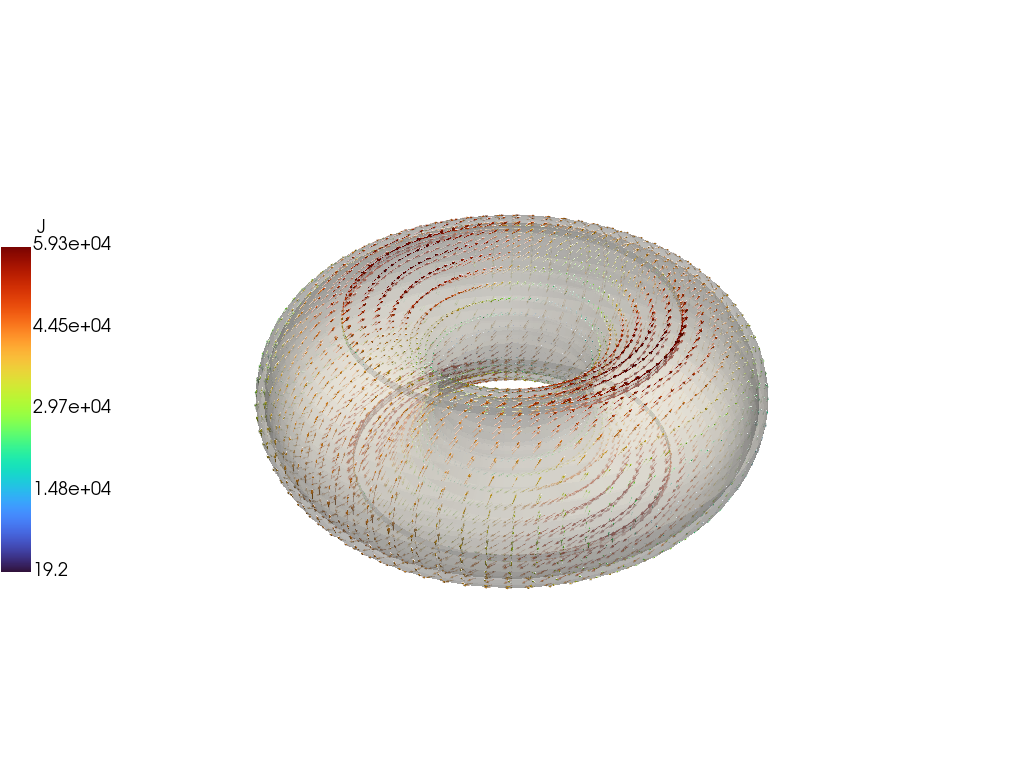

In [9]:
tw_nested.save_current(eig_vecs[1,:],'J_02')
plot_data = tw_nested.build_XDMF()
if have_pyvista:
    grid = plot_data['ThinCurr']['smesh'].get_pyvista_grid()
    J_02 = plot_data['ThinCurr']['smesh'].get_field('J_02_v')
    grid["vectors"] = J_02
    grid.set_active_vectors("vectors")
    p = pyvista.Plotter()
    scale = 0.1/(np.linalg.norm(J_02,axis=1)).max()
    arrows = grid.glyph(scale="vectors", orient="vectors", factor=scale)
    p.add_mesh(arrows, cmap="turbo", scalar_bar_args={'title': "J", "vertical": True, "position_y":0.25, "position_x": 0.0})
    p.add_mesh(grid, color="white", opacity=0.4, show_edges=False)
    p.show()

## Run time-domain simulation
We now use \ref OpenFUSIONToolkit.ThinCurr.ThinCurr.run_td "run_td()" to perform a time-domain simulation with the
same coil current waveform as \ref doc_tCurr_hodlr: we simulate 40 ms using a timestep of 0.2 ms (200 steps), and
ramp the current in the I-coil down from 1 MA to zero over the first 4 ms. The first column of `coil_currs` specifies
time points in ascending order and the remaining columns the coil currents at each time point. As the full
self-inductance matrix is available we use a direct solver (`direct=True`).

In [10]:
dt = 2.E-4
nsteps = 200
coil_currs = np.array([
    [0.0, 1.E6],
    [4.E-3, 0.0],
    [1.0, 0.0]
])
tw_nested.run_td(dt,nsteps,status_freq=20,coil_currs=coil_currs,sensor_obj=sensor_obj,direct=True)


Starting time-domain simulation
  timestep    time           sol_norm     nits    solver time
  Starting factorization
 Inverting real matrix


   Time =    1.1445421450000000     


      20    4.000000E-03    6.6486E+00       1        0.02


      40    8.000000E-03    5.7435E+00       1        0.02


      60    1.200000E-02    5.4667E+00       1        0.02


      80    1.600000E-02    5.2246E+00       1        0.02


... (2 outputs left out)

     140    2.800000E-02    4.5825E+00       1        0.02


     160    3.200000E-02    4.3909E+00       1        0.01


     180    3.600000E-02    4.2084E+00       1        0.02


     200    4.000000E-02    4.0345E+00       1        0.02


### Compute B-field reconstruction operator and generate plot files from run

In [11]:
_, Bc = tw_nested.compute_Bmat()
tw_nested.plot_td(nsteps,compute_B=True,sensor_obj=sensor_obj)
_ = tw_nested.build_XDMF()

Building element->element magnetic reconstruction operator


Building vcoil->element magnetic reconstruction operator


Building icoil->element magnetic reconstruction operator

Post-processing time-domain simulation



Creating output files: oft_xdmf.XXXX.h5
  Removing old Xdmf files
    Removed 2 files
  Found Group: thincurr
    Found Mesh: icoils
      # of blocks: 1
    Found Mesh: smesh
      # of blocks: 1


### Load and plot sensor signals from time-domain run
The sensor signals are read from `floops.hist`, which is written to the I/O directory of the model (`nested/`).


OFT History file: nested/floops.hist
  Number of fields = 4
  Number of entries = 201

  Fields:
    time: Simulation time [s] (d1)
    Bz_out: No description (d1)
    Br_top: No description (d1)
    Bz_in: No description (d1)



findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.


findfont: Failed to find font weight bold for cmmi10, now using 400.


findfont: Failed to find font weight bold for cmsy10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for cmtt10, now using 400.


findfont: Failed to find font weight bold for cmti10, now using 400.


findfont: Failed to find font weight bold for cmb10, now using 400.


findfont: Failed to find font weight bold for cmss10, now using 400.


findfont: Failed to find font weight bold for cmex10, now using 400.


findfont: Failed to find font weight bold for DejaVu Sans Display, now using 400.


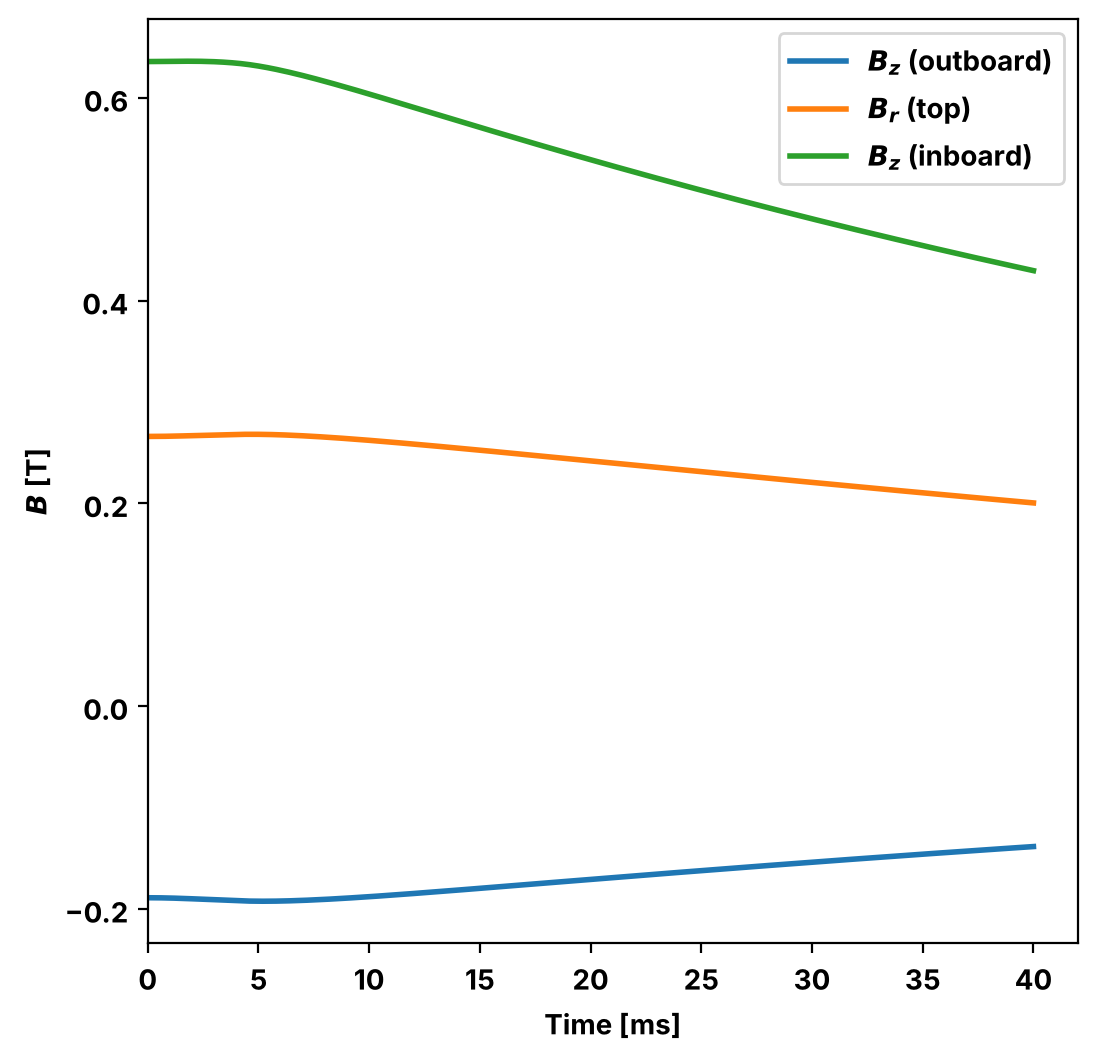

In [12]:
hist_file = histfile('nested/floops.hist')
print(hist_file)

fig, ax = plt.subplots(1,1)
for field, label in (('Bz_out', r'$B_z$ (outboard)'), ('Br_top', r'$B_r$ (top)'), ('Bz_in', r'$B_z$ (inboard)')):
    ax.plot(hist_file['time']*1.E3,hist_file[field],label=label)
ax.set_xlim(left=0.0)
ax.legend()
ax.set_xlabel('Time [ms]')
_ = ax.set_ylabel(r'$B$ [T]')

While the coil current is ramped down (the first 4 ms), currents induced in the tori and ribs keep the field at the
sensors nearly constant. After the coil current reaches zero, the signals decay with the time constant of the slowest
axisymmetric mode (about 97 ms). As the coil drives only axisymmetric, toroidal current, which does not cross the ribs, the sensor
signals are the same if the ribs are insulated (`tw_insulated`). A non-axisymmetric drive, such as a tilted or
off-center coil, would show the effect of the ribs.